In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Зареждане
df = pd.read_csv(
    "data/traffic_aggregated.csv",
    parse_dates=["datetime"]
)

print(f"Редове  : {len(df):,}")
print(f"Колони  : {list(df.columns)}")

# Feature Engineering
df["hour"]      = df["datetime"].dt.hour
df["dow"]       = df["datetime"].dt.dayofweek
df["month"]     = df["datetime"].dt.month
df["direction_enc"] = (df["direction"] == "Център").astype(int)

# Синусоидални трансформации за цикличните features
# hour: 0-23 е цикличен — 23 и 0 са близки!
df["hour_sin"]  = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"]  = np.cos(2 * np.pi * df["hour"] / 24)
df["dow_sin"]   = np.sin(2 * np.pi * df["dow"] / 7)
df["dow_cos"]   = np.cos(2 * np.pi * df["dow"] / 7)
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

print(f"\nFeatures след engineering:")
feature_cols = ["hour", "dow", "month", "direction_enc",
                "hour_sin", "hour_cos", "dow_sin", "dow_cos",
                "month_sin", "month_cos"]
print(df[feature_cols].head(6).to_string(index=False))

Редове  : 52,608
Колони  : ['datetime', 'direction', 'volume', 'avg_speed']

Features след engineering:
 hour  dow  month  direction_enc  hour_sin  hour_cos   dow_sin   dow_cos  month_sin  month_cos
    0    5      1              1  0.000000  1.000000 -0.974928 -0.222521        0.5   0.866025
    0    5      1              0  0.000000  1.000000 -0.974928 -0.222521        0.5   0.866025
    1    5      1              1  0.258819  0.965926 -0.974928 -0.222521        0.5   0.866025
    1    5      1              0  0.258819  0.965926 -0.974928 -0.222521        0.5   0.866025
    2    5      1              1  0.500000  0.866025 -0.974928 -0.222521        0.5   0.866025
    2    5      1              0  0.500000  0.866025 -0.974928 -0.222521        0.5   0.866025


In [2]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings("ignore")

print("=" * 60)
print("KNN — HYPERPARAMETER TUNING")
print("=" * 60)

# Features
feature_cols = ["hour_sin", "hour_cos", "dow_sin", "dow_cos",
                "month_sin", "month_cos", "direction_enc"]

# Тренировъчни данни — само валидни стойности
train_data = df[df["volume"].notna()].copy().reset_index(drop=True)

X = train_data[feature_cols].values
y = train_data["volume"].values

print(f"Тренировъчни редове: {len(train_data):,}")
print(f"Features           : {feature_cols}")

# TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)

# Тестваме различни k стойности
k_values = [3, 5, 7, 10, 15, 20, 30, 50]
tuning_results = []

for k in k_values:
    mae_scores  = []
    rmse_scores = []
    
    for fold, (train_idx, val_idx) in enumerate(tscv.split(X)):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]
        
        knn = KNeighborsRegressor(n_neighbors=k, metric="euclidean")
        knn.fit(X_train, y_train)
        y_pred = knn.predict(X_val)
        
        mae_scores.append(mean_absolute_error(y_val, y_pred))
        rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))
    
    tuning_results.append({
        "k"        : k,
        "MAE_mean" : np.mean(mae_scores).round(2),
        "MAE_std"  : np.std(mae_scores).round(2),
        "RMSE_mean": np.mean(rmse_scores).round(2),
        "RMSE_std" : np.std(rmse_scores).round(2)
    })
    print(f"  k={k:>3}: MAE={np.mean(mae_scores):.2f} ± {np.std(mae_scores):.2f}, "
          f"RMSE={np.mean(rmse_scores):.2f} ± {np.std(rmse_scores):.2f}")

tuning_df = pd.DataFrame(tuning_results)
best_k = tuning_df.loc[tuning_df["MAE_mean"].idxmin(), "k"]
print(f"\nОптимално k: {best_k} (най-нисък MAE)")
print(tuning_df.to_string(index=False))

KNN — HYPERPARAMETER TUNING
Тренировъчни редове: 35,983
Features           : ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'direction_enc']
  k=  3: MAE=216.79 ± 34.20, RMSE=313.49 ± 39.16
  k=  5: MAE=219.35 ± 24.25, RMSE=308.52 ± 32.46
  k=  7: MAE=220.44 ± 19.21, RMSE=309.27 ± 25.49
  k= 10: MAE=219.07 ± 20.59, RMSE=304.35 ± 26.23
  k= 15: MAE=220.43 ± 19.43, RMSE=302.12 ± 23.04
  k= 20: MAE=220.77 ± 17.37, RMSE=298.06 ± 20.65
  k= 30: MAE=218.01 ± 17.02, RMSE=289.08 ± 19.57
  k= 50: MAE=216.78 ± 15.28, RMSE=284.18 ± 17.00

Оптимално k: 50 (най-нисък MAE)
 k  MAE_mean  MAE_std  RMSE_mean  RMSE_std
 3    216.79    34.20     313.49     39.16
 5    219.35    24.25     308.52     32.46
 7    220.44    19.21     309.27     25.49
10    219.07    20.59     304.35     26.23
15    220.43    19.43     302.12     23.04
20    220.77    17.37     298.06     20.65
30    218.01    17.02     289.08     19.57
50    216.78    15.28     284.18     17.00


In [3]:
# Разширяваме търсенето
k_values_extended = [50, 75, 100, 150, 200, 300]
tuning_results_ext = []

for k in k_values_extended:
    mae_scores  = []
    rmse_scores = []
    
    for fold, (train_idx, val_idx) in enumerate(tscv.split(X)):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]
        
        knn = KNeighborsRegressor(n_neighbors=k, metric="euclidean")
        knn.fit(X_train, y_train)
        y_pred = knn.predict(X_val)
        
        mae_scores.append(mean_absolute_error(y_val, y_pred))
        rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))
    
    tuning_results_ext.append({
        "k"        : k,
        "MAE_mean" : np.mean(mae_scores).round(2),
        "MAE_std"  : np.std(mae_scores).round(2),
        "RMSE_mean": np.mean(rmse_scores).round(2),
        "RMSE_std" : np.std(rmse_scores).round(2)
    })
    print(f"  k={k:>3}: MAE={np.mean(mae_scores):.2f} ± {np.std(mae_scores):.2f}, "
          f"RMSE={np.mean(rmse_scores):.2f} ± {np.std(rmse_scores):.2f}")

tuning_df_ext = pd.DataFrame(tuning_results_ext)
best_k = tuning_df_ext.loc[tuning_df_ext["MAE_mean"].idxmin(), "k"]
print(f"\nОптимално k в разширения диапазон: {best_k}")

  k= 50: MAE=216.78 ± 15.28, RMSE=284.18 ± 17.00
  k= 75: MAE=219.23 ± 15.11, RMSE=283.80 ± 17.24
  k=100: MAE=219.34 ± 16.70, RMSE=281.37 ± 18.98
  k=150: MAE=219.67 ± 18.93, RMSE=279.28 ± 20.08
  k=200: MAE=219.06 ± 19.22, RMSE=275.97 ± 20.51
  k=300: MAE=221.53 ± 19.96, RMSE=277.13 ± 20.73

Оптимално k в разширения диапазон: 50


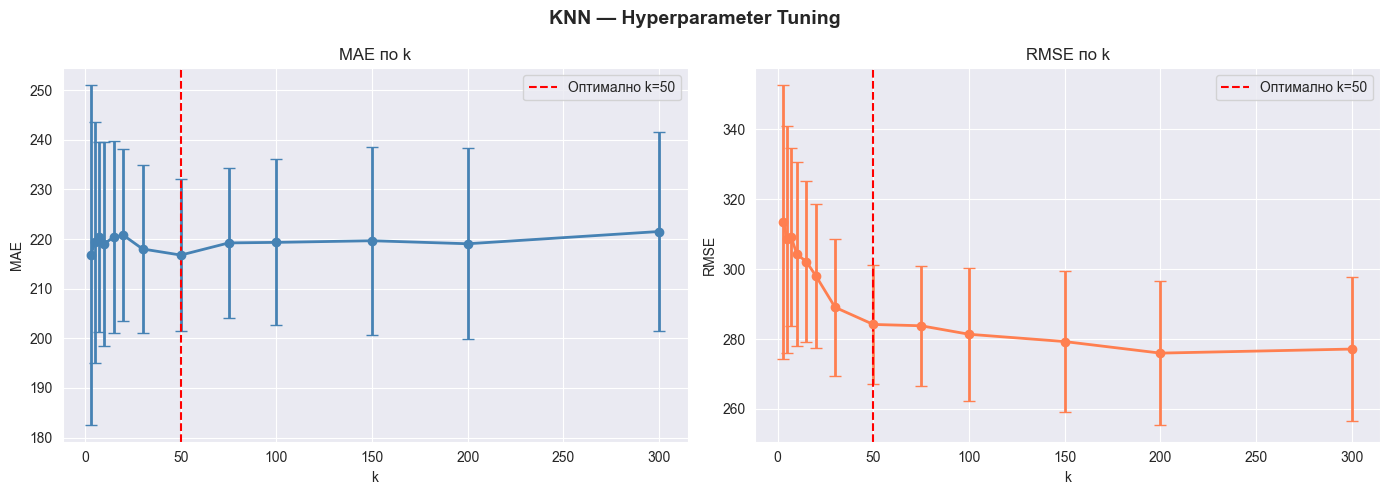

Финално k = 50


In [4]:
# Визуализация на tuning резултатите
all_tuning = pd.concat([
    pd.DataFrame(tuning_results),
    tuning_df_ext[tuning_df_ext["k"] > 50]
]).reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("KNN — Hyperparameter Tuning", fontsize=14, fontweight="bold")

# MAE
ax1.errorbar(all_tuning["k"], all_tuning["MAE_mean"],
             yerr=all_tuning["MAE_std"],
             marker="o", linewidth=2, color="steelblue", capsize=4)
ax1.axvline(x=50, color="red", linestyle="--", label="Оптимално k=50")
ax1.set_title("MAE по k")
ax1.set_xlabel("k")
ax1.set_ylabel("MAE")
ax1.legend()

# RMSE
ax2.errorbar(all_tuning["k"], all_tuning["RMSE_mean"],
             yerr=all_tuning["RMSE_std"],
             marker="o", linewidth=2, color="coral", capsize=4)
ax2.axvline(x=50, color="red", linestyle="--", label="Оптимално k=50")
ax2.set_title("RMSE по k")
ax2.set_xlabel("k")
ax2.set_ylabel("RMSE")
ax2.legend()

plt.tight_layout()
plt.savefig("knn_tuning.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Финално k = 50")
best_k = 50

In [5]:
print("=" * 60)
print("KNN ИМПУТАЦИЯ — ТЕСТОВИ ПЕРИОДИ")
print("=" * 60)

# Evaluation функции
def evaluate(y_true, y_pred, period_name):
    mask   = ~np.isnan(y_true) & ~np.isnan(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    mae    = mean_absolute_error(y_true, y_pred)
    rmse   = np.sqrt(mean_squared_error(y_true, y_pred))
    return {"period": period_name, "MAE": round(mae, 2), "RMSE": round(rmse, 2)}

def create_test_set(df, start, end):
    mask   = (df["datetime"] >= start) & (df["datetime"] <= end)
    subset = df[mask].copy().reset_index(drop=True)
    subset["volume_true"] = subset["volume"]
    subset["volume"]      = np.nan
    return subset

test_periods = {
    "short_1" : ("2023-06-05", "2023-06-07"),
    "short_2" : ("2023-11-05", "2023-11-07"),
    "short_3" : ("2023-12-05", "2023-12-07"),
    "medium_1": ("2023-06-05", "2023-06-18"),
    "medium_2": ("2023-11-05", "2023-11-18"),
    "medium_3": ("2023-12-05", "2023-12-18"),
    "long_1"  : ("2023-06-01", "2023-06-30"),
    "long_2"  : ("2023-11-01", "2023-11-30"),
    "long_3"  : ("2023-12-01", "2023-12-31"),
}

def knn_imputation(df, test_df, start, end, k=50):
    # Тренировъчни данни
    train = df[
        ((df["datetime"] < start) | (df["datetime"] > end)) &
        (df["volume"].notna())
    ].copy()

    X_train = train[feature_cols].values
    y_train = train["volume"].values

    # Обучение
    knn = KNeighborsRegressor(n_neighbors=k, metric="euclidean")
    knn.fit(X_train, y_train)

    # Предсказване
    result = test_df.copy()
    X_test = result[feature_cols].values
    result["volume_imputed"] = knn.predict(X_test).round(2)

    return result

# Прилагаме за всички 9 периода
results_knn = []

for name, (start, end) in test_periods.items():
    test    = create_test_set(df, start, end)
    imputed = knn_imputation(df, test, start, end, k=best_k)
    score   = evaluate(
        imputed["volume_true"].values,
        imputed["volume_imputed"].values,
        name
    )
    score["category"] = name.split("_")[0]
    results_knn.append(score)
    print(f"  {name:<12}: MAE={score['MAE']:>7.2f}, RMSE={score['RMSE']:>7.2f}")

results_knn_df = pd.DataFrame(results_knn)
print(f"\nСредно по категория:")
print(results_knn_df.groupby("category")[["MAE","RMSE"]]
      .mean().round(2).to_string())

KNN ИМПУТАЦИЯ — ТЕСТОВИ ПЕРИОДИ
  short_1     : MAE= 265.02, RMSE= 323.76
  short_2     : MAE=  78.27, RMSE= 103.83
  short_3     : MAE=  50.41, RMSE=  72.30
  medium_1    : MAE= 270.83, RMSE= 330.64
  medium_2    : MAE=  93.29, RMSE= 125.36
  medium_3    : MAE=  50.62, RMSE=  65.06
  long_1      : MAE= 305.67, RMSE= 371.70
  long_2      : MAE=  77.17, RMSE= 110.95
  long_3      : MAE=  67.63, RMSE=  97.02

Средно по категория:
             MAE    RMSE
category                
long      150.16  193.22
medium    138.25  173.69
short     131.23  166.63


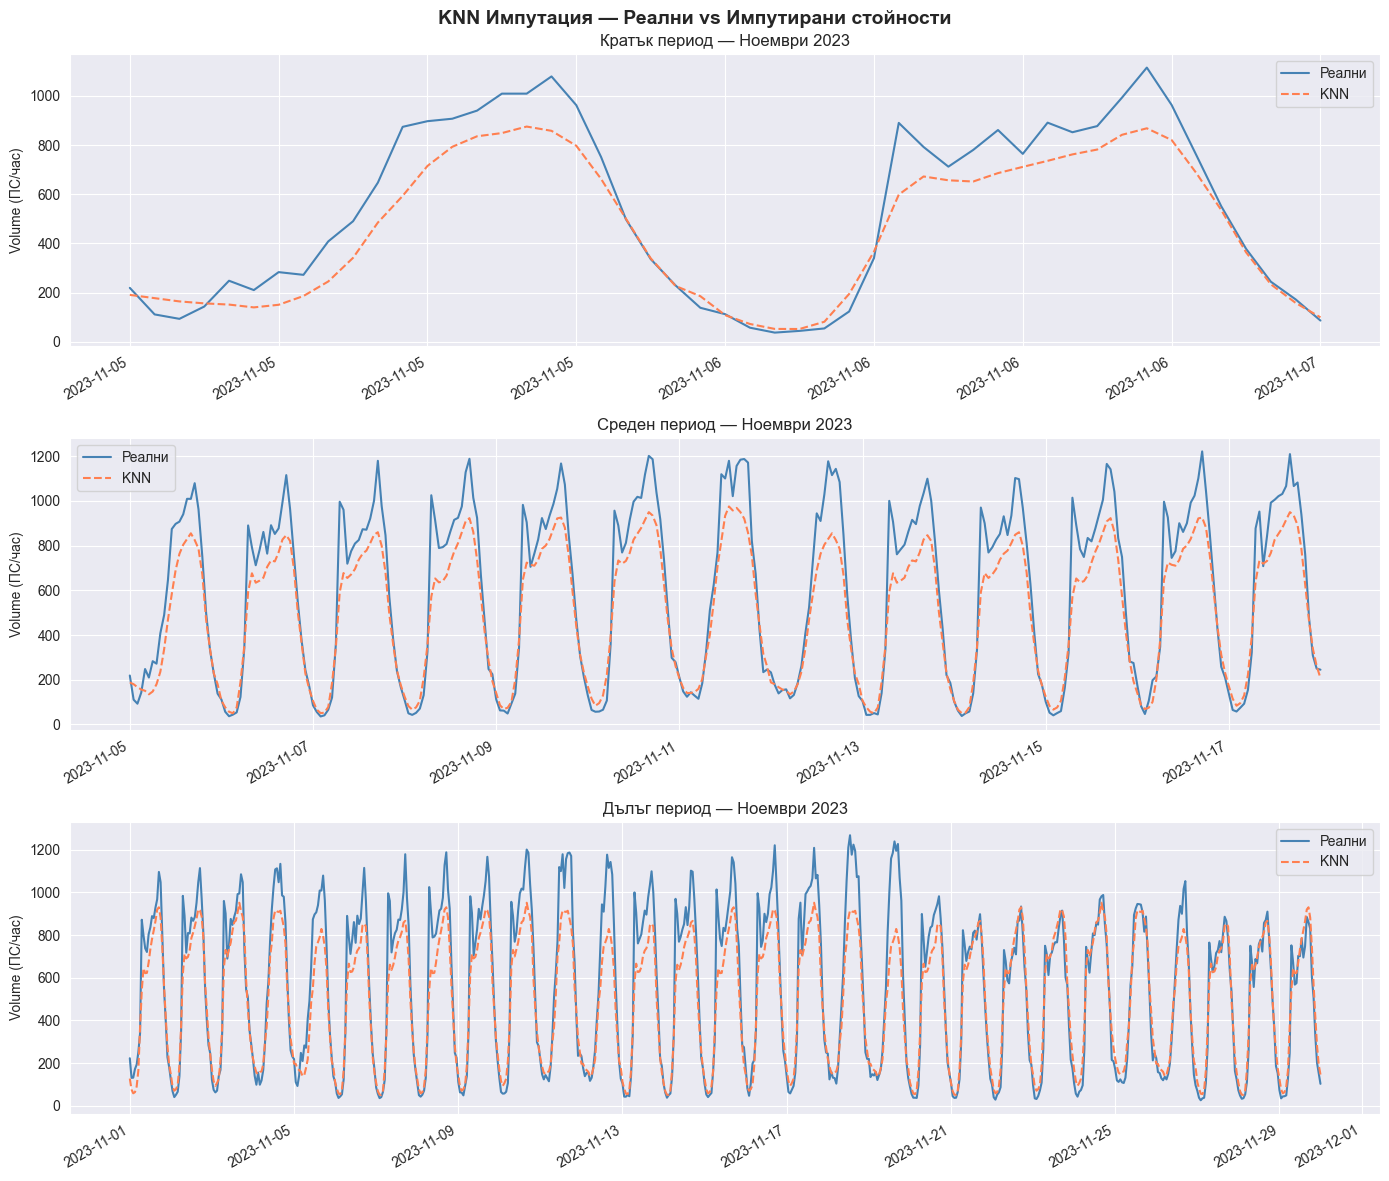

In [6]:
# Визуализация — сравнение реални vs импутирани стойности
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
fig.suptitle("KNN Импутация — Реални vs Импутирани стойности", 
             fontsize=14, fontweight="bold")

examples = [
    ("short_2",  "Кратък период — Ноември 2023"),
    ("medium_2", "Среден период — Ноември 2023"),
    ("long_2",   "Дълъг период — Ноември 2023"),
]

for ax, (period_name, title) in zip(axes, examples):
    start, end = test_periods[period_name]
    test    = create_test_set(df, start, end)
    imputed = knn_imputation(df, test, start, end, k=best_k)

    # Само посока "Център" за прегледност
    sub = imputed[imputed["direction"] == "Център"]

    ax.plot(sub["datetime"], sub["volume_true"],
            color="steelblue", linewidth=1.5, label="Реални")
    ax.plot(sub["datetime"], sub["volume_imputed"],
            color="coral", linewidth=1.5, linestyle="--", label="KNN")
    ax.set_title(title)
    ax.set_ylabel("Volume (ПС/час)")
    ax.legend()
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("knn_imputation.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Запазване на KNN резултатите
results_knn_df.to_csv("data/results_knn.csv", index=False)
print("Запазено в data/results_knn.csv")

Запазено в data/results_knn.csv
